# 4. Comprar, ou alugar e investir em fundos imobiliários?

Este é o notebook central do projeto. A hipótese a testar:

> *Hoje compensa mais morar de aluguel e montar uma carteira de fundos imobiliários do que comprar um imóvel.*

## Como a conta é feita

Duas pessoas começam com o mesmo dinheiro e **gastam exatamente o mesmo todo mês**.

| | Compradora | Inquilina |
|---|---|---|
| No primeiro dia | Paga a entrada (20%) e os custos da compra (5%: ITBI, escritura, registro). Financia o resto pelo sistema SAC. | Aplica esses mesmos 25% do valor do imóvel em fundos imobiliários. |
| Todo mês | Paga a parcela e a manutenção (1% do valor do imóvel ao ano). | Paga o aluguel de um imóvel equivalente, reajustado uma vez por ano. |
| A diferença | Quem gastou menos no mês investe a diferença nos mesmos fundos. No começo é a inquilina; perto do fim do financiamento, a compradora. | |
| No fim | Imóvel (menos 6% de corretagem para vender), menos a dívida, mais a carteira. | Carteira, menos 20% de imposto sobre o ganho de capital. |

Condomínio e IPTU ficam de fora porque, no Brasil, quem mora paga os dois, seja dono ou inquilino.

O resultado é a **vantagem do aluguel**: o patrimônio da inquilina menos o da compradora, em valores do dia da
compra e como percentual do preço do imóvel. **Acima de zero, alugar e investir ganhou; abaixo, comprar ganhou.**

O código está em `src/comprar_ou_alugar/simulador.py` e tem testes para cada regra desta tabela.

In [1]:
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import TwoSlopeNorm

from comprar_ou_alugar import analise, cenarios, estilo
from comprar_ou_alugar.caminhos import TRATADOS
from comprar_ou_alugar.estilo import br, pct
from comprar_ou_alugar.simulador import Cenario, simular

estilo.aplicar()

cidades = pd.read_parquet(TRATADOS / "cidades.parquet")
mensal = pd.read_parquet(TRATADOS / "mensal.parquet")

TRES_CIDADES = ["São Paulo", "Rio de Janeiro", "Belo Horizonte"]
series = {cidade: cenarios.serie_da_cidade(cidades, mensal, cidade) for cidade in TRES_CIDADES}
hoje = {cidade: cenarios.parametros_de_hoje(series[cidade]) for cidade in TRES_CIDADES}

pd.DataFrame(
    {
        cidade: {
            "apartamento de 65 m²": f"R$ {br(p.valor_imovel)}",
            "aluguel equivalente": f"R$ {br(p.aluguel_mensal)} por mês",
            "rentabilidade do aluguel": pct(analise.anualizar(p.aluguel_mensal / p.valor_imovel), 1) + " ao ano",
            "juros do financiamento": pct(p.juros_aa, 1) + " ao ano",
        }
        for cidade, p in hoje.items()
    }
)

,São Paulo,Rio de Janeiro,Belo Horizonte
apartamento de 65 m²,R$ 789.308,R$ 729.059,R$ 693.356
aluguel equivalente,R$ 4.249 por mês,R$ 3.991 por mês,R$ 3.274 por mês
rentabilidade do aluguel,"6,7% ao ano","6,8% ao ano","5,8% ao ano"
juros do financiamento,"11,3% ao ano","11,3% ao ano","11,3% ao ano"


Estes são os números de quem decide **hoje** (último mês do FipeZAP; taxa média de financiamento imobiliário para
pessoa física, do Banco Central).

## Um exemplo para entender a mecânica

São Paulo, 30 anos, em um cenário simples de taxas fixas: inflação de 4,5% ao ano, imóvel e aluguel acompanhando
a inflação e a carteira rendendo 3% ao ano acima dela (perto do que o IFIX entregou desde 2011).

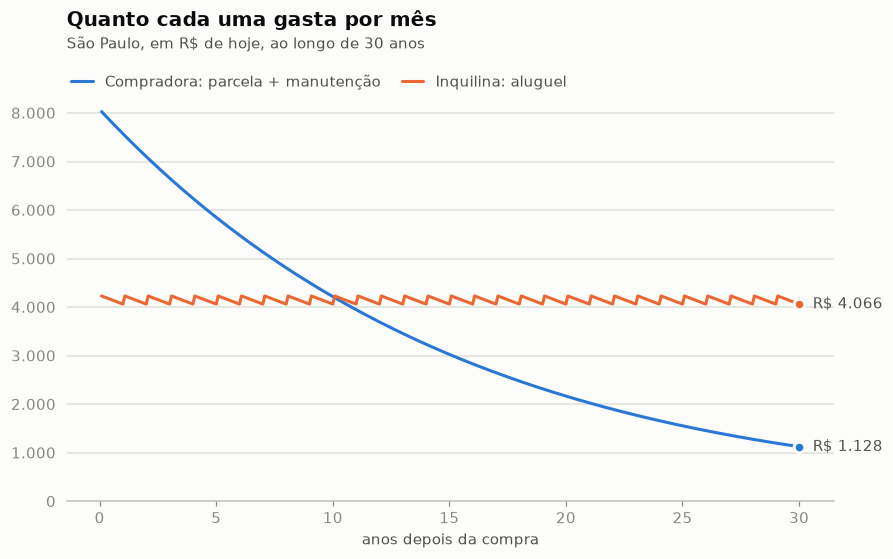

A parcela fica menor que o aluguel depois de 10,2 anos.


In [2]:
INFLACAO = 0.045


def nominal(real_aa: float) -> float:
    return (1 + real_aa) * (1 + INFLACAO) - 1


exemplo = simular(
    hoje["São Paulo"],
    Cenario.constante(
        360,
        valorizacao_aa=nominal(0),
        reajuste_aluguel_aa=nominal(0),
        carteira_retorno_aa=nominal(0.03),
        carteira_rendimento_aa=0.085,
        inflacao_aa=INFLACAO,
    ),
).tabela()
exemplo["ano"] = exemplo["mes"] / 12
reais = exemplo[["gasto_comprador", "aluguel", "patrimonio_comprador", "patrimonio_inquilino"]].div(
    exemplo["deflator"], axis=0
)

fig, ax = plt.subplots()
ax.plot(exemplo["ano"][1:], reais["gasto_comprador"][1:], color=estilo.AZUL, label="Compradora: parcela + manutenção")
ax.plot(exemplo["ano"][1:], reais["aluguel"][1:], color=estilo.LARANJA, label="Inquilina: aluguel")
estilo.titulo(ax, "Quanto cada uma gasta por mês", "São Paulo, em R$ de hoje, ao longo de 30 anos", legenda=True)
estilo.eixo_br(ax.yaxis)
ax.set_ylim(0)
ax.set_xlabel("anos depois da compra")
estilo.rotular_fins(ax, lambda v: f"R$ {br(v)}")
plt.show()

cruzamento = exemplo.loc[exemplo["gasto_comprador"] < exemplo["aluguel"], "ano"].iloc[1]
print(f"A parcela fica menor que o aluguel depois de {br(cruzamento, 1)} anos.")

No sistema SAC a parcela começa alta e cai todo mês; o aluguel, em termos reais, fica parado (e dá um degrau a
cada reajuste anual). Durante os primeiros anos a inquilina gasta bem menos e investe a diferença. Depois a
situação se inverte, e ao fim do financiamento a compradora só tem a manutenção para pagar.

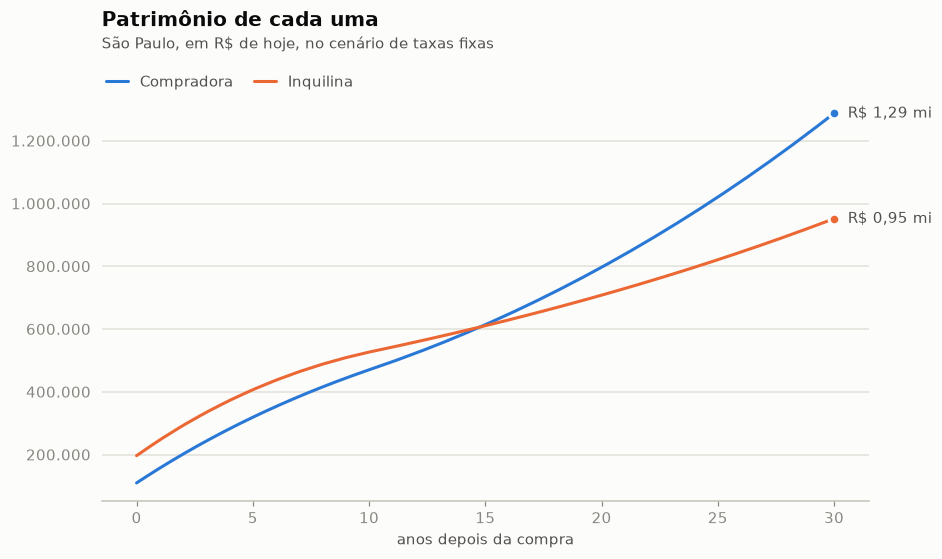

A inquilina sai na frente; a compradora passa depois de 14,8 anos.


In [3]:
fig, ax = plt.subplots()
ax.plot(exemplo["ano"], reais["patrimonio_comprador"], color=estilo.AZUL, label="Compradora")
ax.plot(exemplo["ano"], reais["patrimonio_inquilino"], color=estilo.LARANJA, label="Inquilina")
estilo.titulo(ax, "Patrimônio de cada uma", "São Paulo, em R$ de hoje, no cenário de taxas fixas", legenda=True)
estilo.eixo_br(ax.yaxis)
ax.set_xlabel("anos depois da compra")
estilo.rotular_fins(ax, lambda v: f"R$ {br(v / 1e6, 2)} mi")
plt.show()

empate = exemplo.loc[(exemplo["patrimonio_comprador"] > exemplo["patrimonio_inquilino"]) & (exemplo["mes"] > 0), "ano"]
print(f"A inquilina sai na frente; a compradora passa depois de {br(empate.iloc[0], 1)} anos.")

A inquilina começa na frente porque comprar custa caro: 5% na entrada e 6% de corretagem se a compradora precisar
vender. Neste cenário a compradora só alcança a inquilina depois de vários anos, e termina com mais.

Um cenário de taxas fixas serve para entender a mecânica, não para decidir. As próximas seções trocam as taxas
fixas por história de verdade.

## 1. Backtest: o que teria acontecido

Para cada mês desde dezembro de 2010 (o início do IFIX), a simulação usa os preços, os aluguéis e a taxa de
financiamento daquele mês e segue os dados reais dali em diante: valorização do m², reajuste do aluguel, IFIX e
inflação.

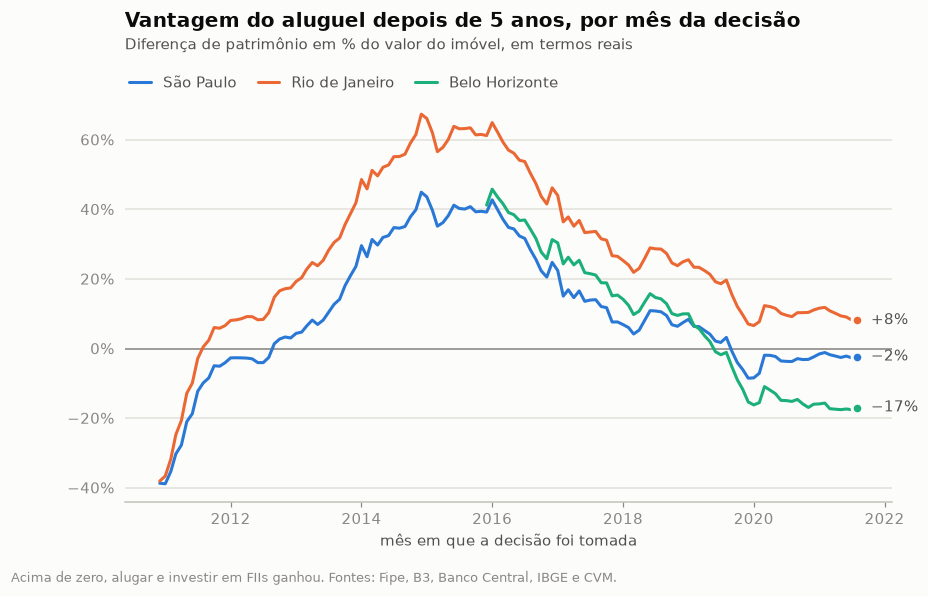

In [4]:
backtests = {
    (cidade, anos): cenarios.backtest(series[cidade], anos).set_index("inicio")
    for cidade in TRES_CIDADES
    for anos in (5, 10)
}


def grafico_backtest(anos: int, subtitulo: str):
    fig, ax = plt.subplots()
    for cidade in TRES_CIDADES:
        ax.plot(backtests[cidade, anos]["vantagem_do_aluguel"], color=estilo.CORES_CIDADES[cidade], label=cidade)
    estilo.titulo(ax, f"Vantagem do aluguel depois de {anos} anos, por mês da decisão", subtitulo, legenda=True)
    estilo.linha_de_base(ax)
    estilo.eixo_pct(ax.yaxis, passo=0.2)
    ax.set_xlabel("mês em que a decisão foi tomada")
    estilo.rotular_fins(ax, lambda v: pct(v, sinal=True))
    estilo.fonte(fig, "Acima de zero, alugar e investir em FIIs ganhou. Fontes: Fipe, B3, Banco Central, IBGE e CVM.")
    return fig


grafico_backtest(5, "Diferença de patrimônio em % do valor do imóvel, em termos reais")
plt.show()

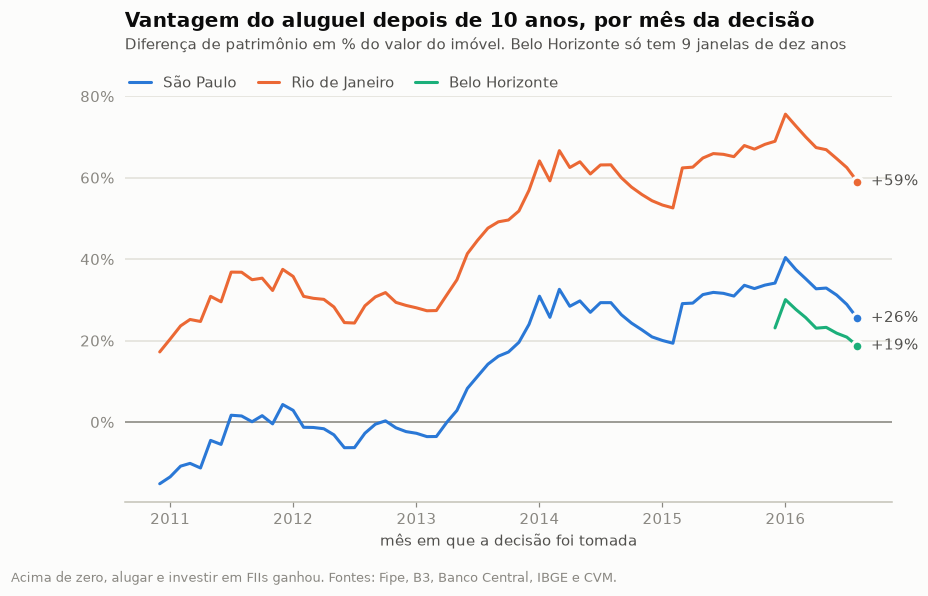

In [5]:
grafico_backtest(10, "Diferença de patrimônio em % do valor do imóvel. Belo Horizonte só tem 9 janelas de dez anos")
plt.show()

In [6]:
linhas = []
for (cidade, anos), resultado in backtests.items():
    vantagem = resultado["vantagem_do_aluguel"]
    linhas.append(
        {
            "cidade": cidade,
            "horizonte": f"{anos} anos",
            "decisões entre": f"{vantagem.index[0]:%m/%Y} e {vantagem.index[-1]:%m/%Y}",
            "janelas": len(vantagem),
            "alugar ganhou em": pct((vantagem > 0).mean()),
            "vantagem mediana": pct(vantagem.median(), sinal=True),
            "pior para alugar": f"{pct(vantagem.min(), sinal=True)} ({vantagem.idxmin():%m/%Y})",
            "melhor para alugar": f"{pct(vantagem.max(), sinal=True)} ({vantagem.idxmax():%m/%Y})",
        }
    )
pd.DataFrame(linhas).set_index(["cidade", "horizonte"])

decisões entre  janelas alugar ganhou em  \
cidade         horizonte                                                
São Paulo      5 anos     12/2010 e 08/2021      129              65%   
               10 anos    12/2010 e 08/2016       69              68%   
Rio de Janeiro 5 anos     12/2010 e 08/2021      129              94%   
               10 anos    12/2010 e 08/2016       69             100%   
Belo Horizonte 5 anos     12/2015 e 08/2021       69              61%   
               10 anos    12/2015 e 08/2016        9             100%   

                         vantagem mediana pior para alugar melhor para alugar  
cidade         horizonte                                                       
São Paulo      5 anos                 +7%   −39% (01/2011)     +45% (12/2014)  
               10 anos               +17%   −15% (12/2010)     +40% (01/2016)  
Rio de Janeiro 5 anos                +25%   −38% (12/2010)     +67% (12/2014)  
               10 anos               +50%   +17% (12/2010)     +76% (01/2016)  
Belo Horizonte 5 anos                +10%   −18% (07/2021)     +46% (01/2016)  
               10 anos               +23%   +19% (08/2016)     +30% (01/2016)

O que o passado mostra:

- **No Rio, alugar e investir ganhou quase sempre**, e com folga. Quem comprou perto do pico de 2014 viu o imóvel
  perder quase metade do valor real.
- **Em São Paulo e Belo Horizonte, alugar ganhou em cerca de dois terços das janelas**, mas o resultado virou
  conforme a data: comprar em 2011 foi um ótimo negócio; comprar em 2014 ou 2015, um péssimo.
- **As diferenças são grandes.** Em cinco anos, chegaram a 39% do valor do imóvel a favor de quem comprou e a 67%
  a favor de quem alugou.

Dois avisos sobre este backtest. As janelas se sobrepõem (a de janeiro e a de fevereiro de 2012 compartilham 59
dos 60 meses), então 129 janelas não são 129 experimentos independentes. E quinze anos contêm um único ciclo
imobiliário completo: alta até 2014, queda longa depois.

### O que explica o resultado de cada janela

Quase tudo se resume à valorização do imóvel no período. Cada ponto abaixo é uma janela de cinco anos.

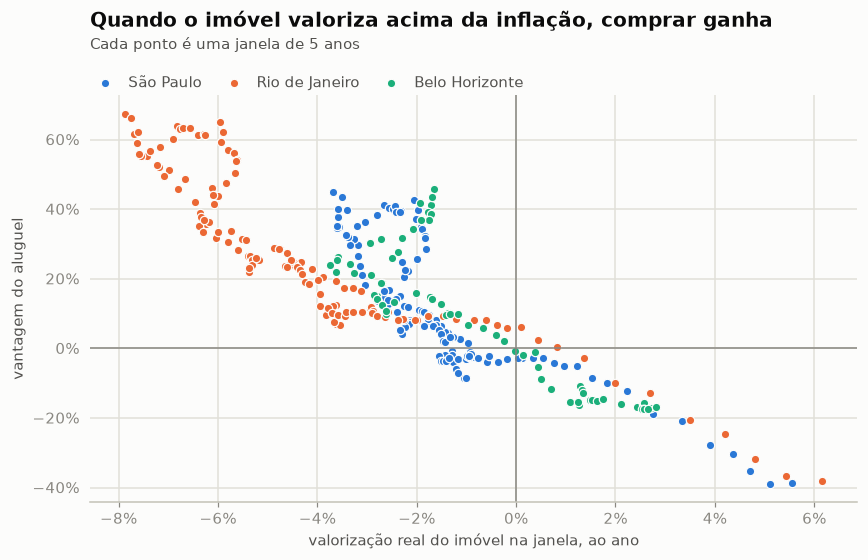

Correlação entre valorização real e vantagem do aluguel: -0,88


In [7]:
fig, ax = plt.subplots()
for cidade in TRES_CIDADES:
    janelas = backtests[cidade, 5]
    ax.scatter(
        janelas["valorizacao_real_aa"],
        janelas["vantagem_do_aluguel"],
        s=30,
        color=estilo.CORES_CIDADES[cidade],
        edgecolors=estilo.SUPERFICIE,
        linewidths=0.8,
        label=cidade,
    )
estilo.titulo(
    ax,
    "Quando o imóvel valoriza acima da inflação, comprar ganha",
    "Cada ponto é uma janela de 5 anos",
    legenda=True,
)
estilo.linha_de_base(ax)
ax.axvline(0, color=estilo.TINTA_SUAVE, lw=1, zorder=1)
ax.grid(axis="x")
estilo.eixo_pct(ax.xaxis, passo=0.02)
estilo.eixo_pct(ax.yaxis, passo=0.2)
ax.set_xlabel("valorização real do imóvel na janela, ao ano")
ax.set_ylabel("vantagem do aluguel")
plt.show()

todas = pd.concat([backtests[cidade, 5] for cidade in TRES_CIDADES])
print(
    f"Correlação entre valorização real e vantagem do aluguel: {br(todas['valorizacao_real_aa'].corr(todas['vantagem_do_aluguel']), 2)}"
)

### E se a carteira fosse de renda fixa?

A mesma conta, com a diferença investida no CDI em vez de FIIs (com 15% de imposto sobre o ganho), nas mesmas
janelas.

In [8]:
linhas = []
for cidade in TRES_CIDADES:
    for anos in (5, 10):
        fiis = backtests[cidade, anos]["vantagem_do_aluguel"]
        cdi = cenarios.backtest(series[cidade], anos, investimento="cdi").set_index("inicio")["vantagem_do_aluguel"]
        cdi = cdi.reindex(fiis.index)  # o CDI tem história mais longa; ficam só as janelas comuns
        linhas.append(
            {
                "cidade": cidade,
                "horizonte": f"{anos} anos",
                "alugar ganhou (FIIs)": pct((fiis > 0).mean()),
                "alugar ganhou (CDI)": pct((cdi > 0).mean()),
                "vantagem mediana (FIIs)": pct(fiis.median(), sinal=True),
                "vantagem mediana (CDI)": pct(cdi.median(), sinal=True),
                "FIIs melhores que CDI em": pct((fiis > cdi).mean()),
            }
        )
pd.DataFrame(linhas).set_index(["cidade", "horizonte"])

alugar ganhou (FIIs) alugar ganhou (CDI)  \
cidade         horizonte                                            
São Paulo      5 anos                     65%                 84%   
               10 anos                    68%                 67%   
Rio de Janeiro 5 anos                     94%                 94%   
               10 anos                   100%                100%   
Belo Horizonte 5 anos                     61%                 67%   
               10 anos                   100%                100%   

                         vantagem mediana (FIIs) vantagem mediana (CDI)  \
cidade         horizonte                                                  
São Paulo      5 anos                        +7%                    +8%   
               10 anos                      +17%                   +15%   
Rio de Janeiro 5 anos                       +25%                   +26%   
               10 anos                      +50%                   +48%   
Belo Horizonte 5 anos                       +10%                   +11%   
               10 anos                      +23%                   +24%   

                         FIIs melhores que CDI em  
cidade         horizonte                           
São Paulo      5 anos                         46%  
               10 anos                        71%  
Rio de Janeiro 5 anos                         47%  
               10 anos                        70%  
Belo Horizonte 5 anos                         39%  
               10 anos                        56%

## 2. Monte Carlo: e daqui para a frente?

O backtest responde "o que teria acontecido". Para quem decide hoje, a pergunta é outra, e o ponto de partida
também: os aluguéis estão mais caros em relação aos preços do que em qualquer momento da última década
(notebook 2), e os juros do financiamento estão acima de 11% ao ano.

A simulação parte das **condições de hoje** e sorteia 10 mil futuros de 30 anos. Cada futuro é montado com
blocos de 12 meses consecutivos tirados da história da cidade, levando junto imóvel, aluguel, IFIX e inflação
do mesmo período. Isso preserva a relação entre as séries e os ciclos de curto prazo.

A limitação é importante: o sorteio só combina o que já aconteceu desde 2011, quando o IFIX começa (em Belo
Horizonte, desde 2016). A alta forte dos imóveis de 2008 a 2010 fica de fora, e se os próximos 30 anos forem de
um regime diferente (juros reais baixos por muito tempo, por exemplo), estes caminhos não o representam.

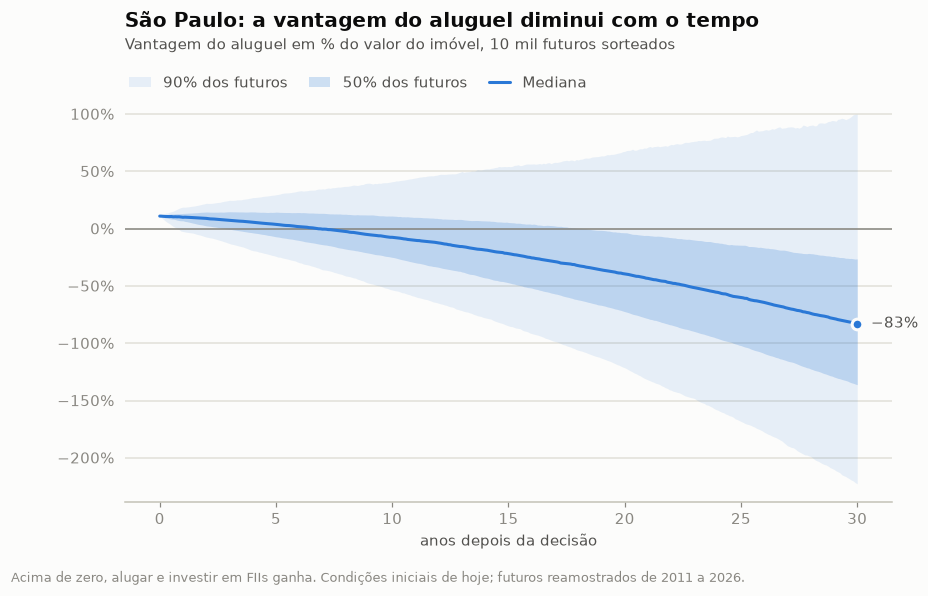

In [9]:
CAMINHOS = 10_000
simulacoes = {
    cidade: cenarios.monte_carlo(series[cidade], hoje[cidade], anos=30, caminhos=CAMINHOS).vantagem_do_aluguel()
    for cidade in TRES_CIDADES
}
anos = np.arange(361) / 12

faixas = np.quantile(simulacoes["São Paulo"], [0.05, 0.25, 0.50, 0.75, 0.95], axis=0)

fig, ax = plt.subplots()
ax.fill_between(anos, faixas[0], faixas[4], color=estilo.AZUL, alpha=0.10, lw=0, label="90% dos futuros")
ax.fill_between(anos, faixas[1], faixas[3], color=estilo.AZUL, alpha=0.22, lw=0, label="50% dos futuros")
ax.plot(anos, faixas[2], color=estilo.AZUL, label="Mediana")
estilo.titulo(
    ax,
    "São Paulo: a vantagem do aluguel diminui com o tempo",
    "Vantagem do aluguel em % do valor do imóvel, 10 mil futuros sorteados",
    legenda=True,
)
estilo.linha_de_base(ax)
estilo.eixo_pct(ax.yaxis, passo=0.5)
ax.set_xlabel("anos depois da decisão")
estilo.rotular_fins(ax, lambda v: pct(v, sinal=True))
estilo.fonte(
    fig,
    "Acima de zero, alugar e investir em FIIs ganha. Condições iniciais de hoje; futuros reamostrados de 2011 a 2026.",
)
plt.show()

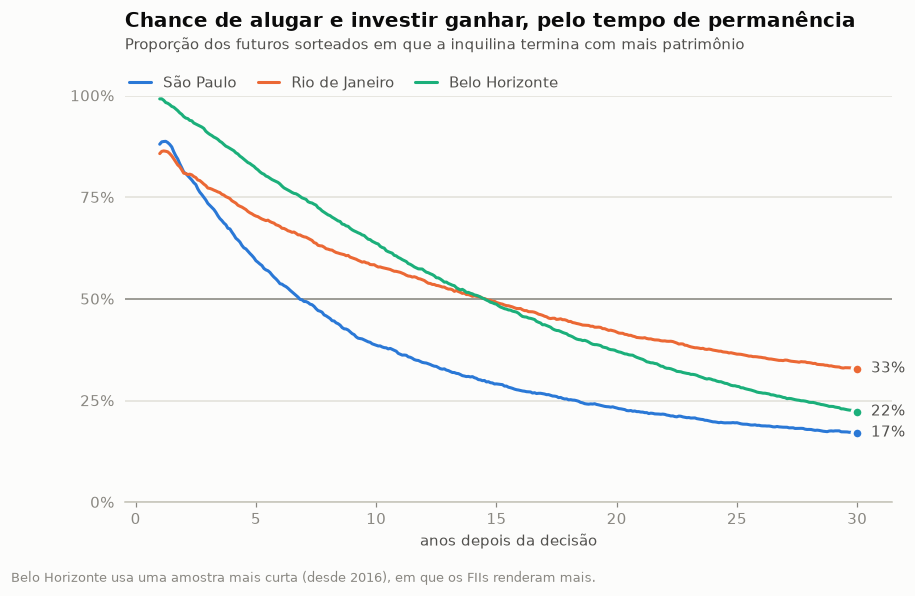

,São Paulo,Rio de Janeiro,Belo Horizonte
anos,,,
3.0,74%,77%,91%
5.0,59%,70%,82%
10.0,39%,58%,64%
15.0,29%,49%,49%
20.0,23%,42%,37%
30.0,17%,33%,22%


In [10]:
chance = pd.DataFrame({cidade: (vantagem > 0).mean(axis=0) for cidade, vantagem in simulacoes.items()}, index=anos)

fig, ax = plt.subplots()
for cidade in TRES_CIDADES:
    ax.plot(chance[cidade].loc[1:], color=estilo.CORES_CIDADES[cidade], label=cidade)
estilo.titulo(
    ax,
    "Chance de alugar e investir ganhar, pelo tempo de permanência",
    "Proporção dos futuros sorteados em que a inquilina termina com mais patrimônio",
    legenda=True,
)
estilo.linha_de_base(ax, 0.5)
estilo.eixo_pct(ax.yaxis, passo=0.25)
ax.set_ylim(0, 1)
ax.set_xlabel("anos depois da decisão")
estilo.rotular_fins(ax, lambda v: pct(v))
estilo.fonte(fig, "Belo Horizonte usa uma amostra mais curta (desde 2016), em que os FIIs renderam mais.")
plt.show()

chance.loc[[3, 5, 10, 15, 20, 30]].map(pct).rename_axis("anos")

O padrão é o mesmo nas três cidades:

- **Até uns cinco anos, alugar e investir é a aposta melhor.** Os custos de comprar e vender (11% do valor do
  imóvel) pesam demais para quem fica pouco tempo.
- **Em prazos longos, comprar passa a ganhar na maioria dos futuros.** Em São Paulo, a chance de a inquilina
  terminar na frente cai abaixo de 50% por volta do sétimo ano, para perto de 40% em dez anos e de 20% em vinte.
  No Rio e em Belo Horizonte a virada demora mais, perto de 15 anos.

Por quê? Com as condições de hoje, a inquilina paga um aluguel de 6% a 7% do valor do imóvel por ano e investe
em um ativo que, na amostra, rendeu só 3% ao ano acima da inflação. A compradora paga juros altos, mas a dívida
encolhe e o aluguel que ela deixa de pagar não.

## 3. Sensibilidade: onde fica o ponto de equilíbrio

O Monte Carlo depende da história. Esta seção faz o caminho inverso: para cada combinação de **valorização real
do imóvel** e **retorno real da carteira**, mantidos fixos por 20 anos, qual lado ganha? O aluguel acompanha o
preço do imóvel.

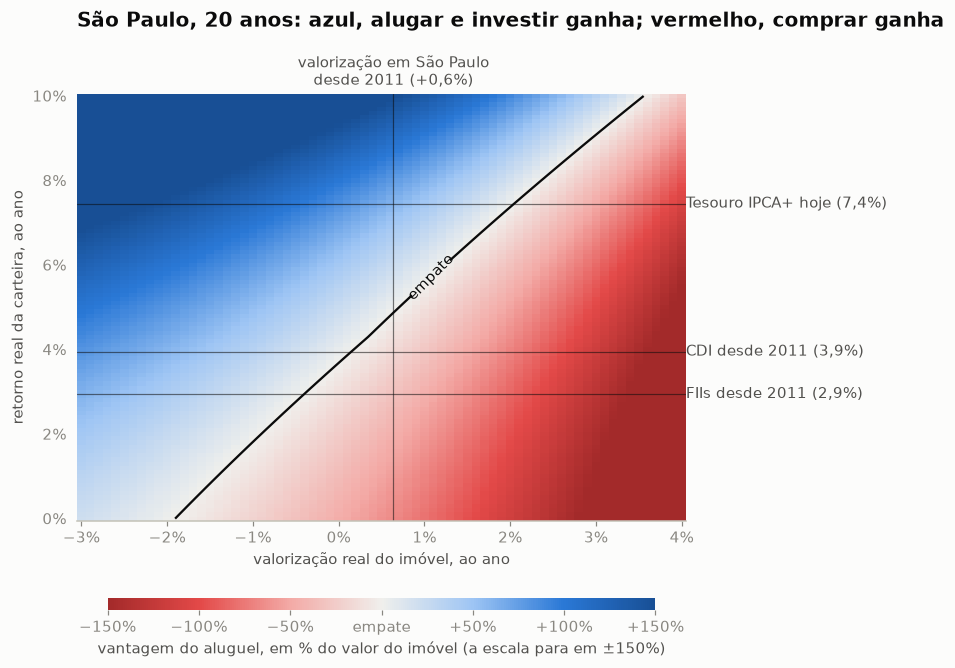

In [11]:
ANOS_SENSIBILIDADE = 20
valorizacoes = np.linspace(-0.03, 0.04, 71)
retornos = np.linspace(0, 0.10, 101)
grade = cenarios.sensibilidade(
    hoje["São Paulo"], anos=ANOS_SENSIBILIDADE, valorizacao_real_aa=valorizacoes, carteira_retorno_real_aa=retornos
)

indicadores = mensal.set_index("data")
serie_sp = series["São Paulo"]
amostra = serie_sp.loc["2011-01":, ["ifix_var_mes", "cdi_var_mes", "ipca_var_mes", "valorizacao_mes"]].dropna()
real_aa = (1 + amostra).prod() ** (12 / len(amostra))
referencias = {
    "FIIs desde 2011": real_aa["ifix_var_mes"] / real_aa["ipca_var_mes"] - 1,
    "CDI desde 2011": real_aa["cdi_var_mes"] / real_aa["ipca_var_mes"] - 1,
    "Tesouro IPCA+ hoje": indicadores["tesouro_ipca_taxa_aa"].dropna().iloc[-1],
}
valorizacao_historica = real_aa["valorizacao_mes"] / real_aa["ipca_var_mes"] - 1

fig, ax = plt.subplots(figsize=(9, 7))
limite = 1.5
malha = ax.pcolormesh(
    valorizacoes,
    retornos,
    grade.clip(-limite, limite),
    cmap=estilo.DIVERGENTE,
    norm=TwoSlopeNorm(0, -limite, limite),
    shading="nearest",
    rasterized=True,
)
empate = ax.contour(valorizacoes, retornos, grade, levels=[0], colors=estilo.TINTA, linewidths=1.5)
ax.clabel(empate, fmt=lambda _: "empate", fontsize=9.5)

for nome, taxa in referencias.items():
    ax.axhline(taxa, color=estilo.TINTA, lw=0.8, alpha=0.55)
    ax.text(0.0405, taxa, f"{nome} ({pct(taxa, 1)})", va="center", fontsize=9.5, color=estilo.TINTA_SECUNDARIA)
ax.axvline(valorizacao_historica, color=estilo.TINTA, lw=0.8, alpha=0.55)
ax.text(
    valorizacao_historica,
    0.1015,
    f"valorização em São Paulo\ndesde 2011 ({pct(valorizacao_historica, 1, sinal=True)})",
    ha="center",
    va="bottom",
    fontsize=9.5,
    color=estilo.TINTA_SECUNDARIA,
)

ax.grid(False)
estilo.eixo_pct(ax.xaxis, passo=0.01)
estilo.eixo_pct(ax.yaxis, passo=0.02)
ax.set_xlabel("valorização real do imóvel, ao ano")
ax.set_ylabel("retorno real da carteira, ao ano")
fig.subplots_adjust(right=0.74)
barra = fig.colorbar(
    malha, ax=ax, orientation="horizontal", pad=0.13, shrink=0.9, aspect=45, ticks=[-1.5, -1, -0.5, 0, 0.5, 1, 1.5]
)
barra.ax.set_xticklabels(["−150%", "−100%", "−50%", "empate", "+50%", "+100%", "+150%"])
barra.outline.set_visible(False)
barra.set_label("vantagem do aluguel, em % do valor do imóvel (a escala para em ±150%)")
ax.set_title(
    f"São Paulo, {ANOS_SENSIBILIDADE} anos: azul, alugar e investir ganha; vermelho, comprar ganha",
    loc="left",
    fontsize=13,
    fontweight="bold",
    pad=44,
)
plt.show()

A mesma grade em números, para algumas combinações (vantagem do aluguel em % do valor do imóvel):

In [12]:
resumida = cenarios.sensibilidade(
    hoje["São Paulo"],
    anos=ANOS_SENSIBILIDADE,
    valorizacao_real_aa=np.array([-0.02, -0.01, 0.0, 0.01, 0.02, 0.03]),
    carteira_retorno_real_aa=np.array([0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08]),
)
resumida.index = [pct(v) for v in resumida.index]
resumida.columns = [pct(v, sinal=True) for v in resumida.columns]
resumida.rename_axis(index="retorno real da carteira", columns="valorização real do imóvel").map(
    lambda v: pct(v, sinal=True)
)

valorização real do imóvel,−2%,−1%,0%,+1%,+2%,+3%
retorno real da carteira,,,,,,
2%,+26%,+2%,−25%,−58%,−97%,−142%
3%,+42%,+17%,−11%,−45%,−84%,−131%
4%,+60%,+35%,+6%,−29%,−69%,−117%
5%,+81%,+55%,+24%,−11%,−52%,−101%
6%,+104%,+77%,+46%,+10%,−33%,−83%
7%,+131%,+103%,+71%,+34%,−10%,−60%
8%,+163%,+135%,+101%,+63%,+18%,−34%


In [13]:
linhas = []
for prazo in (10, 20, 30):
    for valorizacao in (-0.01, 0.0, 0.01, 0.02):
        coluna = cenarios.sensibilidade(
            hoje["São Paulo"],
            anos=prazo,
            valorizacao_real_aa=np.array([valorizacao]),
            carteira_retorno_real_aa=np.linspace(0, 0.12, 241),
        ).iloc[:, 0]
        linhas.append(
            {
                "prazo": f"{prazo} anos",
                "valorização real": pct(valorizacao, sinal=True),
                "empate": coluna[coluna > 0].index.min(),
            }
        )
equilibrio = pd.DataFrame(linhas).pivot(index="prazo", columns="valorização real", values="empate")
print("Retorno real da carteira a partir do qual alugar e investir ganha (São Paulo):")
equilibrio[[pct(v, sinal=True) for v in (-0.01, 0.0, 0.01, 0.02)]].map(lambda v: pct(v, 1))

Retorno real da carteira a partir do qual alugar e investir ganha (São Paulo):


valorização real,−1%,0%,+1%,+2%
prazo,,,,
10 anos,"0,0%","1,7%","4,0%","6,5%"
20 anos,"1,8%","3,7%","5,6%","7,4%"
30 anos,"2,6%","4,3%","5,9%","7,5%"


Esta é a leitura mais útil do projeto:

- Se o imóvel só acompanhar a inflação, **a carteira precisa render perto de 4% ao ano acima da inflação** para a
  inquilina empatar em 20 a 30 anos.
- **O IFIX entregou menos que isso desde 2011** (2,9%). Por isso o Monte Carlo, que reamostra essa história,
  favorece a compra no longo prazo.
- **O Tesouro IPCA+ paga hoje bem mais que isso.** Com o juro real nos níveis atuais, quem aluga e trava essa
  taxa ganha de quem compra, a menos que os imóveis voltem a subir entre 1% e 2% ao ano acima da inflação. (A taxa
  do gráfico é bruta; com 15% de imposto sobre o ganho, o retorno real líquido fica um a dois pontos abaixo.)
- A cada ponto percentual a mais de valorização real do imóvel, a carteira precisa render quase dois pontos a
  mais para compensar.

## 4. O que mais muda a resposta

Mesma simulação de Monte Carlo para São Paulo, mudando uma premissa de cada vez.

In [14]:
indicadores_hoje = indicadores[["juros_financiamento_regulado_aa", "juros_financiamento_mercado_aa"]].dropna().iloc[-1]
base = hoje["São Paulo"]
variacoes = {
    "Premissas do projeto": {},
    f"Juros de {pct(indicadores_hoje['juros_financiamento_regulado_aa'], 1)} (média das taxas reguladas)": {
        "juros_aa": indicadores_hoje["juros_financiamento_regulado_aa"]
    },
    f"Juros de {pct(indicadores_hoje['juros_financiamento_mercado_aa'], 1)} (média das taxas de mercado)": {
        "juros_aa": indicadores_hoje["juros_financiamento_mercado_aa"]
    },
    "Entrada de 10%": {"entrada_pct": 0.10},
    "Entrada de 50%": {"entrada_pct": 0.50},
    "Tabela Price em vez de SAC": {"sistema": "PRICE"},
    "Manutenção de 0,5% ao ano": {"manutencao_aa": 0.005},
    "Manutenção de 1,5% ao ano": {"manutencao_aa": 0.015},
    "Investe só metade da diferença": {"disciplina": 0.5},
    "Não investe a diferença": {"disciplina": 0.0},
}

linhas = {}
for nome, ajuste in variacoes.items():
    vantagem = cenarios.monte_carlo(serie_sp, replace(base, **ajuste), anos=20, caminhos=CAMINHOS).vantagem_do_aluguel()
    linhas[nome] = {f"{prazo} anos": (vantagem[:, prazo * 12] > 0).mean() for prazo in (5, 10, 20)}
# O CDI tem história desde 2008; para comparar com os FIIs, a amostra sorteada é a mesma (2011 em diante).
em_cdi = cenarios.monte_carlo(
    serie_sp.loc["2011-01":], base, anos=20, caminhos=CAMINHOS, investimento="cdi"
).vantagem_do_aluguel()
linhas["Carteira em CDI em vez de FIIs"] = {
    f"{prazo} anos": (em_cdi[:, prazo * 12] > 0).mean() for prazo in (5, 10, 20)
}

print("Chance de alugar e investir ganhar, em São Paulo:")
pd.DataFrame(linhas).T.map(pct)

Chance de alugar e investir ganhar, em São Paulo:


,5 anos,10 anos,20 anos
Premissas do projeto,59%,39%,23%
"Juros de 10,9% (média das taxas reguladas)",56%,36%,21%
"Juros de 14,2% (média das taxas de mercado)",78%,62%,41%
Entrada de 10%,63%,41%,24%
Entrada de 50%,50%,34%,21%
Tabela Price em vez de SAC,62%,42%,25%
"Manutenção de 0,5% ao ano",53%,31%,16%
"Manutenção de 1,5% ao ano",65%,48%,32%
Investe só metade da diferença,31%,18%,15%
Não investe a diferença,9%,4%,7%


- **A taxa do financiamento é a premissa que mais pesa.** Com juros de mercado (acima de 14% ao ano), alugar passa
  a ser a melhor escolha na maioria dos futuros mesmo em dez anos.
- **A disciplina pesa tanto quanto.** A vantagem do aluguel só existe se a diferença for investida todo mês. Quem
  investe metade perde boa parte dela; quem não investe quase sempre termina atrás. A parcela do financiamento
  funciona como uma poupança forçada, e isso tem valor para muita gente.
- **A manutenção importa mais do que parece**: meio ponto para cima ou para baixo muda a chance em 6 a 9 pontos.
- **Trocar FIIs por CDI não muda a conclusão de longo prazo.** A renda fixa oscila menos, mas na amostra desde
  2011 nenhuma das duas carteiras rendeu o bastante para compensar o aluguel de hoje por 20 anos.
- Entrada e sistema de amortização mexem pouco.

## 5. Os rendimentos dos fundos pagam o aluguel?

Outra forma de ler "viver de aluguel": quanto é preciso ter em FIIs para que os rendimentos mensais cubram o
aluguel do apartamento?

In [15]:
rendimento_mes = indicadores["fii_dividend_yield_mes"].dropna().iloc[-12:].mean()
print(
    f"Rendimento médio dos FIIs nos últimos 12 meses: {pct(rendimento_mes, 2)} ao mês ({pct(rendimento_mes * 12, 1)} ao ano)"
)

pd.DataFrame(
    {
        cidade: {
            "aluguel": f"R$ {br(p.aluguel_mensal)}",
            "carteira necessária": f"R$ {br(p.aluguel_mensal / rendimento_mes)}",
            "preço do apartamento": f"R$ {br(p.valor_imovel)}",
            "carteira ÷ preço do apartamento": pct(p.aluguel_mensal / rendimento_mes / p.valor_imovel),
        }
        for cidade, p in hoje.items()
    }
)

Rendimento médio dos FIIs nos últimos 12 meses: 0,73% ao mês (8,8% ao ano)


,São Paulo,Rio de Janeiro,Belo Horizonte
aluguel,R$ 4.249,R$ 3.991,R$ 3.274
carteira necessária,R$ 579.289,R$ 544.200,R$ 446.457
preço do apartamento,R$ 789.308,R$ 729.059,R$ 693.356
carteira ÷ preço do apartamento,73%,75%,64%


Com cerca de **três quartos do preço do apartamento** aplicados em FIIs, os rendimentos pagam o aluguel dele.
É o argumento mais forte a favor da hipótese: os fundos distribuem mais (perto de 9% ao ano) do que o imóvel
rende de aluguel (6% a 7%).

Mas a conta tem um ponto fraco. O aluguel sobe com a inflação todo ano, e o rendimento dos fundos não
necessariamente: desde 2017, o preço das cotas caiu cerca de 1% ao ano (notebook 3). Quem gasta todo o rendimento
para pagar o aluguel fica com um patrimônio que perde valor real, enquanto o aluguel continua subindo. Para a
conta fechar de forma permanente, é preciso reinvestir uma parte.

## Conclusões

A hipótese era que **hoje** compensa mais alugar e investir em FIIs do que comprar. O que os dados dizem:

1. **No passado recente, ela se confirmou na maioria das vezes.** De 2011 para cá, alugar e investir no IFIX
   venceu em quase todas as janelas no Rio e em cerca de dois terços delas em São Paulo e Belo Horizonte. O
   motivo principal não foi o desempenho dos FIIs (eles perderam até para o CDI), e sim a queda real dos imóveis
   depois de 2014.
2. **Para quem decide hoje, ela vale no curto prazo e não no longo.** Com os aluguéis no nível mais caro em uma
   década, quem vai ficar até uns cinco anos no imóvel tende a sair melhor alugando. Em São Paulo, depois de uns
   sete anos comprar passa a ser o resultado mais provável; no Rio e em Belo Horizonte, a virada fica por volta
   dos 15 anos. Isso se os FIIs renderem o que renderam até aqui.
3. **O que decide é o retorno da carteira.** A inquilina precisa de uns 4% ao ano acima da inflação para empatar
   no longo prazo. O IFIX histórico não chega lá; o Tesouro IPCA+, nos juros de hoje, passa com folga. A pergunta
   "FIIs ou casa própria?" esconde outra mais importante: "em que eu invisto a diferença?".
4. **Sem disciplina, comprar ganha.** Toda a vantagem do aluguel depende de investir a diferença todos os meses,
   por anos.

### Limitações

- **Preços de anúncio e de apartamentos.** O FipeZAP não mede o preço de fechamento nem cobre casas.
- **Um apartamento "médio" não existe.** O índice acompanha um conjunto de imóveis que se renova; um apartamento
  específico envelhece. A manutenção de 1% ao ano tenta cobrir isso, mas é uma premissa.
- **História curta.** O IFIX tem 15 anos e um único ciclo imobiliário. As janelas do backtest se sobrepõem, e o
  Monte Carlo não inventa regimes que a amostra não tem.
- **Custos que ficaram de fora**: seguros obrigatórios do financiamento (MIP e DFI), custos de mudança, FGTS na
  entrada ou na amortização, subsídios do Minha Casa Minha Vida e o imposto sobre o ganho de capital na venda do
  imóvel (que tem isenções).
- **O que não é dinheiro**: a segurança de não depender de um proprietário, a liberdade de reformar, a
  flexibilidade de se mudar. Cada pessoa dá um peso diferente a isso, e nenhum deles entra na conta.